# 12 The final search: exact mode and fast mode
In the earlier notebooks I tuned the hybrid weights (notebook 08) and tested a fast index on the side (notebook 09). Here both go into the real search, `HybridEngine` in `src/product_similarity/hybrid.py`. It has two modes. They are the same hybrid, with all ten parts and the same weights, and they differ only in how the two vector parts (sentence and picture) are searched: the **exact mode** compares with every product, and the **fast mode** uses an HNSW index for each of the two parts. I check that the real search gives the same results as my notebooks, and then I compare the two modes: how good the results are by my ratings, and how much time it saves. Nothing here uses the 20 locked final products: they are hidden from every search.

In [1]:
import json
import os
import sys
from pathlib import Path

import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)  # the project reads data/archive.zip relative to the project folder
sys.path.insert(0, str(root / "experiments"))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

results = root / "results"
match = json.loads((results / "final_search_check.json").read_text(encoding="utf-8"))
check = json.loads((results / "fast_vs_exact_check.json").read_text(encoding="utf-8"))["comparison"]
ratings = json.loads((results / "final_search_ratings.json").read_text(encoding="utf-8"))
print("loaded the saved results")

loaded the saved results


## 1. How the final search works
| Part | What it does |
|---|---|
| Weights | The 4-weight mix from notebook 08: sentence vectors 46%, picture vectors 29%, the seven attributes 23% together (category, brand, audience, price, colour, weight, rating) and the TF-IDF title 3%. A part that a product does not have is skipped, and the other weights are scaled up |
| Vectors | The sentence vectors (MiniLM) and the picture vectors (CLIP) were computed once, offline. The search only reads them, so it never loads a model |
| Exact mode | Compares the sentence and picture vectors with every product, scores every product with all ten parts, puts them in order (ties are decided by the product ID) and returns the best |
| Fast mode | Only the two vector parts are sped up. An HNSW index for the sentence vectors and one for the picture vectors each return the 100 nearest products. Only those (at most 200) are scored with all ten parts, in exactly the same way as in the exact mode. A product without a picture is in the sentence index only, and it is scored with the picture part skipped |
| One copy of each item | Both modes skip results that are the same item as the query or as a better result (same picture link, or picture vectors almost identical). This is the rule my ratings use too |
| Switch | The mode can be chosen for each search (`mode` is `exact` or `fast`), and `PS_SEARCH_MODE` sets the default (`exact`, `fast`, or `baseline` for title and attributes only, used when the vectors are missing) |

In [2]:
from product_similarity.service import build_final_engine

engine = build_final_engine("exact")
query_id = "26d41bdc1495de290bc8e6062d927729"
shown = engine.describe(query_id, 5)
print("query:", shown["query"]["title"][:90])
for r in shown["results"]:
    print(f"  {r['score']:.3f}  {r['title'][:80]}")

query: LA' Facon Cotton Kalamkari Handblock Saree Blouse Fabric 100 cms Black Base Dancers (Cotto
  0.480  Kalamkari Print Cotton Fabric for Women's Clothes Like Kurti, Blouse, Dress, Pat
  0.465  Cotton Kalamkari Handblock Saree Blouse/Kurti Fabric 100 cms Purple Colour - Bud
  0.384  Worldoftextile Women's Cotton Sanganeri Hand Block Jaipuri Dabu Floral Print Sal
  0.383  INAYA HAND BLOCK Printed Cotton Saree With Blouse Piece (MULTI-COLOUR_Free Size)
  0.361  Bagru Print Cotton Fabric for Women's Kurti, Dress, Patiala, Palazzo and Chudida


## 2. Is it the same search as in my notebooks?
For the 30 development products, I compare the top 10 of the real search (exact mode) with the top 10 of the evaluation code behind notebook 08, one by one. The 20 locked products are hidden from the search. `experiments/check_final_search.py` does this.

In [3]:
display(
    pd.DataFrame(
        {
            "same top 10, same order": [
                f"{match['same_list_in_same_order']} of {match['products']}"
            ],
            "nDCG@10, notebooks": [match["notebook"]["ndcg_at_10"]],
            "nDCG@10, real search": [match["real_search_exact"]["ndcg_at_10"]],
            "precision@10, notebooks": [match["notebook"]["precision_at_10"]],
            "precision@10, real search": [match["real_search_exact"]["precision_at_10"]],
        },
        index=["30 development products"],
    )
)

,"same top 10, same order","nDCG@10, notebooks","nDCG@10, real search","precision@10, notebooks","precision@10, real search"
30 development products,30 of 30,0.8105,0.8105,0.8767,0.8767


### What this shows
All 30 products give the same top 10 in the same order, so the real search is the search I tuned and evaluated. (The nDCG@10 is 0.8105, a little higher than the 0.808 in notebook 08, because I have since rated a few more results.)

## 3. The comparison: exact mode against fast mode
My ratings are the truth. I rated every result that either mode returned for the 30 development products, and nDCG@10 and precision@10 are computed from my ratings. The fast mode takes the 100 nearest products from each of the two indexes. Time is the whole search (shortlist, scoring with all ten parts, and one copy per item): 5 runs per product, the fastest kept, the median of the 30 products, one thread.

In [4]:
fast = next(r for r in check["by_candidates"] if r["candidates"] == 100)
display(
    pd.DataFrame(
        [
            {
                "mode": "exact",
                "nDCG@10": check["exact"]["ndcg_at_10"],
                "precision@10": check["exact"]["precision_at_10"],
                "time per search (ms)": check["exact"]["ms_per_query"],
            },
            {
                "mode": "fast (100 from each index)",
                "nDCG@10": fast["ndcg_at_10"],
                "precision@10": fast["precision_at_10"],
                "time per search (ms)": fast["ms_per_query"],
            },
        ]
    ).set_index("mode")
)

,nDCG@10,precision@10,time per search (ms)
mode,,,
exact,0.8105,0.8767,8.473
fast (100 from each index),0.8095,0.8767,0.582


### What this shows
The fast mode gives almost the same quality as the exact mode by my ratings (nDCG@10 is 0.001 lower, precision@10 is the same) and it is about 15 times faster (0.58 ms against 8.5 ms).

My ratings also tell, for each mode, how many of its 300 results (10 for each of the 30 products) I rated 2 (a very similar product), 1 (somewhat similar) and 0 (not similar):

In [5]:
display(
    pd.DataFrame(
        {
            mode: {
                "rated 2": m["rated_2"],
                "rated 1": m["rated_1"],
                "rated 0": m["rated_0"],
                "not rated": m["unrated"],
            }
            for mode, m in ratings["modes"].items()
        }
    ).T
)

,rated 2,rated 1,rated 0,not rated
exact,221,42,37,0
fast,220,43,37,0


## 4. Product by product, by my ratings
For each of the 30 products, I compare the nDCG@10 of the exact mode with the nDCG@10 of the fast mode. Both are computed from my ratings, so my ratings decide which mode is better, not the other mode.

In [6]:
p = ratings["per_product_ndcg"]
print(
    f"same nDCG@10 in both modes: {p['fast_equal_to_exact']} of {p['products_with_something_to_find']} products"
)
print(f"fast mode lower: {p['fast_lower']}, fast mode higher: {p['fast_higher']}")
display(
    pd.DataFrame(p["differing"]).T.rename(
        columns={"exact": "nDCG@10 exact", "fast": "nDCG@10 fast"}
    )
)

same nDCG@10 in both modes: 27 of 30 products
fast mode lower: 2, fast mode higher: 1


,nDCG@10 exact,nDCG@10 fast
Q44,0.2475,0.1839
Q47,0.3843,0.4395
Q49,0.7656,0.7453


### What this shows
27 of the 30 products have exactly the same nDCG@10 in both modes. The fast mode is a little lower for two products (Q44 and Q49) and higher for one (Q47), so there is no clear loss. This is a small sample of 30 products, so I do not read more into these differences.

## 5. Time
The time is the whole search: the shortlist, the scoring of the candidates with all ten parts, and the choice of the final 10 (I had not timed this in notebook 09). It is the median over the 30 products.

| | Exact mode | Fast mode (100 from each index) |
|---|---|---|
| Time per search | 8.5 ms | 0.58 ms |

The fast mode time grows with the number of products taken from each index, because each one is scored with all ten parts: 0.52 ms with 50, 0.58 ms with 100, 0.84 ms with 250 and 1.12 ms with 500. The fast mode also needs the two indexes (114 MB together, built once in about 13 seconds), on top of the vectors (166 MB) that both modes hold.

## 6. Recorded in MLflow
Each run is recorded in the experiment `final-search`: 5 runs (the exact mode, and the fast mode with 50, 100, 250 and 500 nearest products from each index). A run stores its settings, its results (nDCG@10, precision@10, time, memory and build time) and the JSON file as an attachment. The runs tagged `headline = yes` are the exact mode and the fast mode with 100 from each index:

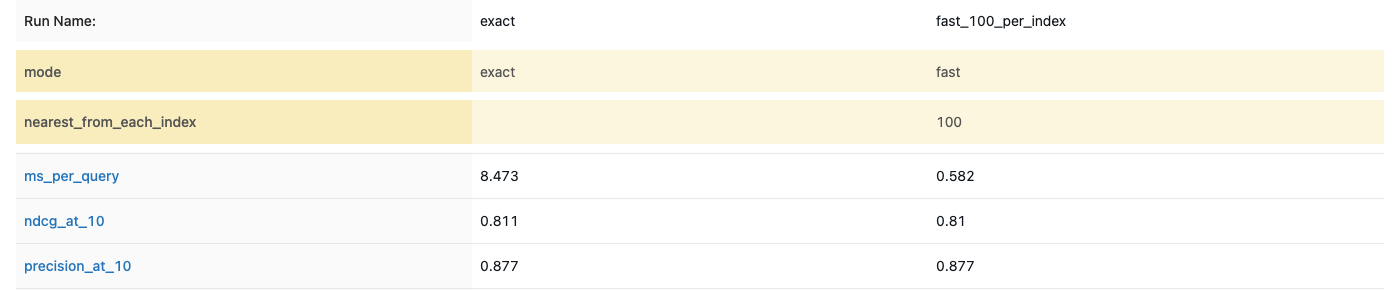

In [7]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_final_search_runs.png", width=800)

## 7. Conclusion

**What I did.** I put the tuned hybrid into the real search, with two modes. Both are the same hybrid, with all ten parts and the same weights. The **exact mode** compares the sentence and picture vectors with every product. The **fast mode** uses HNSW only to speed up those two parts: it takes the 100 nearest products from an index of the sentence vectors and from an index of the picture vectors, and scores only those. First I checked that the real search gives the same results as my notebooks (30 of 30 products). Then I took **my own ratings as the source of truth** for both modes (I rated the 26 new results first) and compared them on the 30 development products, with nDCG@10, precision@10 and the time of one search.

| 30 development products | nDCG@10 | Precision@10 | Time per search |
|---|---|---|---|
| Exact mode | 0.8105 | 0.8767 | 8.5 ms |
| Fast mode (HNSW, 100 from each index) | 0.8095 | 0.8767 | 0.58 ms |

**What I found**

- By my ratings, the two modes are almost the same. nDCG@10 is 0.8105 and 0.8095, and precision@10 is the same. Of the 300 results of each mode, I rated 221 with a 2, 42 with a 1 and 37 with a 0 for the exact mode, and 220, 43 and 37 for the fast mode.
- The fast mode is much faster: 0.58 ms against 8.5 ms, about 15 times. This is the advantage of HNSW.

**Decision.** The exact mode is the default. I will create a page where I can choose between the default (exact) mode and the HNSW (fast) mode, see the time of each search, and tune the weights as well.

**Limitations**

- HNSW needs a little more memory, because its two indexes (114 MB) are kept on top of the vectors (166 MB), and building them takes about 13 seconds, once.
- If a picture vector or a sentence vector is missing, the search works the same in both modes: that part is skipped and the other weights are scaled up. I checked this in a small test, not on the 30 products, because all of them have both vectors.
- I tested only 30 products, with my ratings as the truth.
- My weights were tuned on these same 30 products, so the scores are optimistic. The final test on the 20 locked products comes at the end.
- The fast mode makes its shortlist from the title meaning and the picture only, so a product that matches the query only through its attributes (brand, category, price) may not be on it.
- I did not test a much bigger catalogue, where the fast mode would matter most. The timings are from one laptop, one thread, one query at a time.

**What I do next.** The Docker image with the final search, then Kubernetes and the CI/CD improvements, and then the rest: the stronger API (input checks, error codes and the `mode` option), caching, the page with the weights and the mode switch, and at the end the 20 locked products.